# SplitSnap demo
Walk one receipt photo through the traditional (no-LLM) pipeline: rectify, preprocess, OCR, layout parse, then split the bill.

In [1]:
import sys; sys.path.insert(0, "../src")
import json
import cv2, numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import data, rectify, preprocess, ocr, parse_layout, pipeline

def show(img, title="", figsize=(7, 9)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img, cmap="gray")
    plt.title(title); plt.axis("off")

## 1. Original photo with corners
Green: labelled ground-truth corners. Red: the quad our detector found.

receipt id: 1004


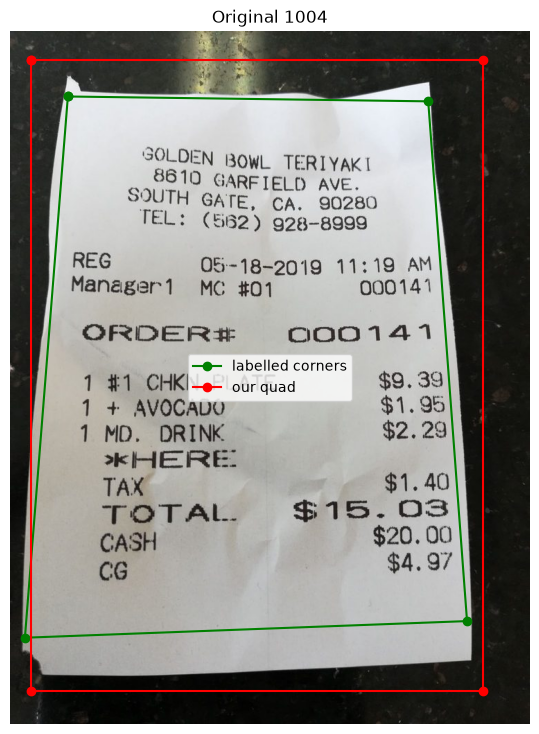

In [2]:
recs = data.load_srd()
rec = next((r for r in recs if r["id"] == "1004"), None) or next(r for r in recs if r["text"])
print("receipt id:", rec["id"])
img = data.load_image(rec["path"])
quad, method = rectify.find_receipt(img)

show(img, f"Original {rec['id']}")
if rec["corners"] is not None:
    gt = np.array(rec["corners"])
    plt.plot(*np.vstack([gt, gt[:1]]).T, "g-o", label="labelled corners")
if quad is not None:
    q = np.array(quad)
    plt.plot(*np.vstack([q, q[:1]]).T, "r-o", label="our quad")
plt.legend(); plt.show()

## 2. Rectified image
A `+crop` suffix means the quad was implausible, so we cropped to its bounding box instead of warping.

method: paper+crop | fallback: False


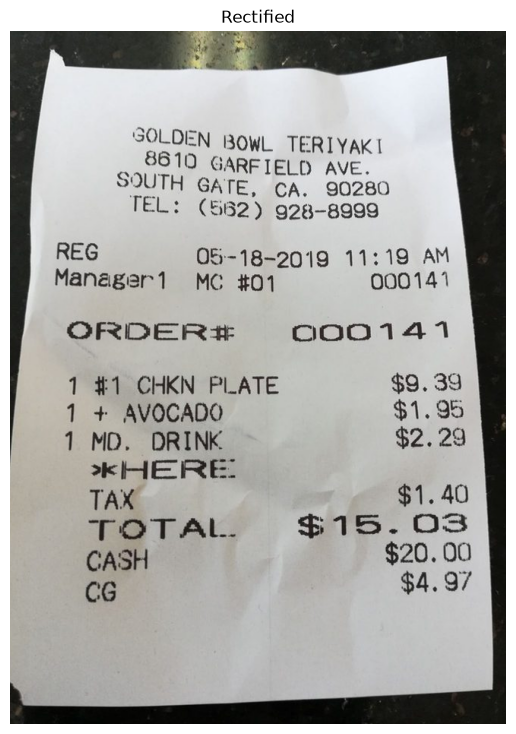

In [3]:
warped, info = rectify.rectify_image(img, mode="ours")
print("method:", info["method"], "| fallback:", info["fallback"])
show(warped, "Rectified"); plt.show()

## 3. Preprocessing
Options and page-segmentation mode (psm) were chosen on the SRD validation split.

options: {'upscale': True, 'clahe': True, 'denoise': True, 'deskew': False, 'binarize': 'sauvola'} | psm: 6


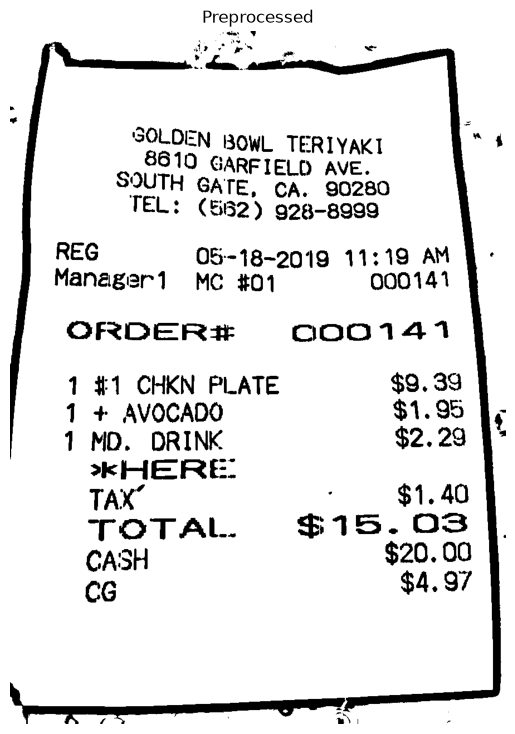

In [4]:
opts, psm = pipeline.best_preprocess()
print("options:", opts, "| psm:", psm)
pre = preprocess.preprocess(warped, opts)
show(pre, "Preprocessed"); plt.show()

## 4. OCR and row grouping
Word boxes are coloured by the text row they were grouped into.

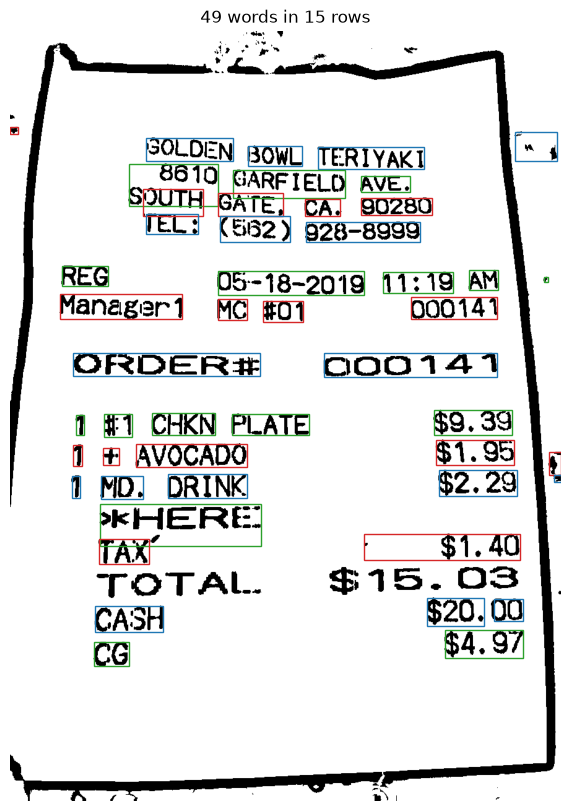

*
SOLDEN BOWL TERIYAKI ss
sone” GARFIELD AVE.
SUTH GATE, CA. 90280
TEL: (882) 928-8989
REG 05-18-2019 11:19 AM IT:
Manager1 MC #01 000141
ORDER: o00141
1 #1 CHKN PLATE $9.39
1 + AVOCADO $1.95 J,
1 MO. DRINK $2.29 4°
*kKHERE-
TAX «$1.40
CASH $20. 00
CG $4.97


In [5]:
text, words = ocr.run_tesseract(pre, psm)
rows = parse_layout.group_rows(words)
colors = ["tab:red", "tab:blue", "tab:green"]
show(pre, f"{len(words)} words in {len(rows)} rows", figsize=(8, 10))
for i, row in enumerate(rows):
    for w in row:
        plt.gca().add_patch(plt.Rectangle((w["left"], w["top"]), w["width"], w["height"],
                                          fill=False, ec=colors[i % 3], lw=1))
plt.show()
for row in rows:
    print(" ".join(w["text"] for w in row))

## 5. Layout parse
Items, subtotal, tax, tip and total are read from the row structure; the checksum tests that the numbers add up.

In [6]:
result = parse_layout.parse_layout(words, "USD", raw_text=text)
print(json.dumps({k: v for k, v in result.items() if k != "raw_text"}, indent=2))
print("checksum:", pipeline.checksum(result))

{
  "items": [
    {
      "name": "CHKN PLATE",
      "qty": 1,
      "price": 9.39
    },
    {
      "name": "AVOCADO",
      "qty": 1,
      "price": 1.95
    },
    {
      "name": "MO. DRINK",
      "qty": 1,
      "price": 2.29
    },
    {
      "name": "CG",
      "qty": 1,
      "price": 4.97
    }
  ],
  "subtotal": null,
  "tax": null,
  "tip": null,
  "total": null
}
checksum: None


## 6. Toy bill split (Alice, Bob, Chen)
Items are assigned round-robin. Tax and tip are split in proportion to each person's item subtotal. If the parse is too poor (fewer than 2 items or no total), a hand-typed receipt is used instead.

In [7]:
people = ["Alice", "Bob", "Chen"]
receipt = result
if len(result["items"]) < 2 or result["total"] is None:
    print("Parse found too few items or no total; using a hand-typed example receipt instead.")
    receipt = {"items": [{"name": "Burger", "qty": 1, "price": 12.50},
                         {"name": "Salad", "qty": 1, "price": 9.00},
                         {"name": "Pasta", "qty": 1, "price": 14.25},
                         {"name": "Fries", "qty": 1, "price": 4.75}],
               "subtotal": 40.50, "tax": 3.24, "tip": None, "total": 43.74}
else:
    print("Using the parsed receipt.")

items = receipt["items"]
subtotal = round(sum(i["price"] for i in items), 2)
tax = receipt["tax"] or 0.0
if receipt["tip"] is not None:
    tip = receipt["tip"]
else:
    tip = round(0.18 * subtotal, 2)
    print(f"No tip parsed: ASSUMING an 18% tip on the subtotal = {tip:.2f}")

assign = {k: people[k % 3] for k in range(len(items))}   # item index -> person
sub = {p: round(sum(i["price"] for k, i in enumerate(items) if assign[k] == p), 2) for p in people}
tax_share = {p: round(tax * sub[p] / subtotal, 2) for p in people}
tip_share = {p: round(tip * sub[p] / subtotal, 2) for p in people}
owes = {p: round(sub[p] + tax_share[p] + tip_share[p], 2) for p in people}

# put any rounding remainder on the first person
target = round(subtotal + tax + tip, 2)
owes[people[0]] = round(owes[people[0]] + (target - sum(owes.values())), 2)

df = pd.DataFrame({"person": people,
                   "items subtotal": [sub[p] for p in people],
                   "tax share": [tax_share[p] for p in people],
                   "tip share": [tip_share[p] for p in people],
                   "owes": [owes[p] for p in people]})
display(df)
print("assignment:", {items[k]["name"]: p for k, p in assign.items()})
print(f"owes sum = {df['owes'].sum():.2f}, subtotal + tax + tip = {target:.2f}")
assert abs(df["owes"].sum() - target) < 0.005

Parse found too few items or no total; using a hand-typed example receipt instead.
No tip parsed: ASSUMING an 18% tip on the subtotal = 7.29


,person,items subtotal,tax share,tip share,owes
0,Alice,17.25,1.38,3.10,21.73
1,Bob,9.00,0.72,1.62,11.34
2,Chen,14.25,1.14,2.57,17.96


assignment: {'Burger': 'Alice', 'Salad': 'Bob', 'Pasta': 'Chen', 'Fries': 'Alice'}
owes sum = 51.03, subtotal + tax + tip = 51.03


This is the traditional (no-LLM) pipeline: classical rectification, preprocessing, Tesseract OCR and a rule-based layout parser. Numbers on this single receipt are illustrative only and say nothing about overall accuracy.